In [34]:
# Install required packages in the notebook environment (run once)
%pip install pandas seaborn matplotlib numpy --quiet

#importing libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

Note: you may need to restart the kernel to use updated packages.


In [35]:
#importing the dataset
data = pd.read_csv('f2.csv')
data.head()

,Temparature,Humidity,Moisture,Soil_Type,Crop_Type,Nitrogen,Potassium,Phosphorous,Fertilizer
0,20,83,26,Clayey,rice,90,49,36,Urea
1,25,84,32,Loamy,rice,66,59,36,Urea
2,33,64,50,Loamy,Wheat,41,0,0,Urea
3,34,65,54,Loamy,Wheat,38,0,0,Urea
4,38,72,51,Loamy,Wheat,39,0,0,Urea


In [36]:
# --- Data cleaning and safe encoding (run immediately after reading the CSV) ---
# Strip whitespace from string columns and standardize column names early
for col in data.select_dtypes(include='object').columns:
    data[col] = data[col].astype(str).str.strip()

# Standardize column names so later cells work reliably
data.rename(columns={'Humidity ':'Humidity','Soil Type':'Soil_Type','Crop Type':'Crop_Type','Fertilizer Name':'Fertilizer'},inplace=True)

# Encode categorical columns with LabelEncoder and keep encoders for later use
from sklearn.preprocessing import LabelEncoder
import pickle
encoders = {}
for col in ['Soil_Type','Crop_Type','Fertilizer']:
    if col in data.columns:
        if data[col].dtype == 'object' or not pd.api.types.is_numeric_dtype(data[col]):
            le = LabelEncoder()
            data[col] = le.fit_transform(data[col].astype(str))
            encoders[col] = le
        else:
            # already numeric (likely encoded) - skip
            pass

# expose encoder variables used later in the notebook for compatibility
if 'Fertilizer' in encoders:
    encode_ferti = encoders['Fertilizer']
    Fertilizer = pd.DataFrame(zip(encode_ferti.classes_,encode_ferti.transform(encode_ferti.classes_)),columns=['Original','Encoded']).set_index('Original')
    display(Fertilizer)

if 'Soil_Type' in encoders:
    encode_soil = encoders['Soil_Type']
    Soil_Type = pd.DataFrame(zip(encode_soil.classes_,encode_soil.transform(encode_soil.classes_)),columns=['Original','Encoded']).set_index('Original')
    display(Soil_Type)

if 'Crop_Type' in encoders:
    encode_crop = encoders['Crop_Type']
    Crop_Type = pd.DataFrame(zip(encode_crop.classes_,encode_crop.transform(encode_crop.classes_)),columns=['Original','Encoded']).set_index('Original')
    display(Crop_Type)

# Persist fertilizer encoder (used later by the app) if present
if 'Fertilizer' in encoders:
    pickle.dump(encoders['Fertilizer'], open('fertilizer.pkl','wb'))

print('Preprocessing complete — string columns stripped and categorical columns encoded (if present).')

,Encoded
Original,
10-10-10,0
10-26-26,1
14-14-14,2
14-35-14,3
15-15-15,4
17-17-17,5
20-20,6
28-28,7
DAP,8


,Encoded
Original,
Black,0
Clayey,1
Loamy,2
Red,3
Sandy,4


,Encoded
Original,
Barley,0
Cotton,1
Ground Nuts,2
Maize,3
Millets,4
Oil seeds,5
Paddy,6
Pulses,7
Sugarcane,8


Preprocessing complete — string columns stripped and categorical columns encoded (if present).


In [37]:
# Define the number of augmented samples to create for each original sample
# increase dataset from 100 rows to 500


# num_augmented_samples = 3

# augmented_data = []

# for index, row in dataset.iterrows():
#     original_sample = row.to_dict()
#     augmented_samples = []

#     for _ in range(num_augmented_samples):
#         augmented_sample = original_sample.copy()
#         augmented_sample['Temparature'] += np.random.normal(0, 0.1)
#         augmented_sample['Humidity'] += np.random.normal(0, 0.1)
#         augmented_sample['Moisture'] += np.random.normal(0, 0.1)
#         augmented_sample['Nitrogen'] += np.random.normal(0, 0.1)
#         augmented_sample['Potassium'] += np.random.normal(0, 0.1)
#         augmented_sample['Phosphorous'] += np.random.normal(0, 0.1)
#         # Add more transformations for other columns as needed
#         augmented_samples.append(augmented_sample)


#     augmented_data.extend(augmented_samples)

# # Convert the augmented data to a DataFrame
# augmented_dataset = pd.DataFrame(augmented_data)

# # Concatenate the original dataset 
# data = pd.concat([dataset, augmented_dataset], ignore_index=True)

In [38]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 552 entries, 0 to 551
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Temparature  552 non-null    int64
 1   Humidity     552 non-null    int64
 2   Moisture     552 non-null    int64
 3   Soil_Type    552 non-null    int64
 4   Crop_Type    552 non-null    int64
 5   Nitrogen     552 non-null    int64
 6   Potassium    552 non-null    int64
 7   Phosphorous  552 non-null    int64
 8   Fertilizer   552 non-null    int64
dtypes: int64(9)
memory usage: 38.9 KB


In [39]:
#changing the column names
data.rename(columns={'Humidity ':'Humidity','Soil Type':'Soil_Type','Crop Type':'Crop_Type','Fertilizer Name':'Fertilizer'},inplace=True)

In [40]:
#checking unique values
data.nunique()

Temparature    21
Humidity       34
Moisture       41
Soil_Type       5
Crop_Type      17
Nitrogen       47
Potassium      31
Phosphorous    36
Fertilizer     14
dtype: int64

In [41]:
#checking for null values
data.isna().sum()

Temparature    0
Humidity       0
Moisture       0
Soil_Type      0
Crop_Type      0
Nitrogen       0
Potassium      0
Phosphorous    0
Fertilizer     0
dtype: int64

In [42]:
data['Fertilizer'].unique()

array([13, 12, 11, 10,  9,  8,  7,  6,  5,  4,  3,  2,  1,  0])

In [43]:
data['Crop_Type'].unique()

array([15, 10,  9,  8,  7, 14,  6,  5,  4,  3,  2,  1, 11, 16,  0, 12, 13])

In [44]:
#statistical parameters
data.describe(include='all')

,Temparature,Humidity,Moisture,Soil_Type,Crop_Type,Nitrogen,Potassium,Phosphorous,Fertilizer
count,552.000000,552.000000,552.000000,552.000000,552.000000,552.000000,552.000000,552.000000,552.000000
mean,28.630435,64.557971,42.840580,2.072464,7.181159,28.521739,10.144928,21.115942,7.434783
std,5.088082,11.880236,11.507275,1.284489,4.718170,29.121989,13.456956,14.920514,3.882029
min,0.000000,50.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,26.000000,54.000000,33.000000,1.000000,3.000000,10.000000,0.000000,8.000000,5.000000
50%,29.000000,62.000000,41.000000,2.000000,7.000000,15.000000,0.000000,20.000000,7.000000
75%,32.000000,68.000000,51.000000,3.000000,11.000000,37.000000,18.000000,36.000000,11.000000
max,38.000000,95.000000,65.000000,4.000000,16.000000,126.000000,59.000000,54.000000,13.000000


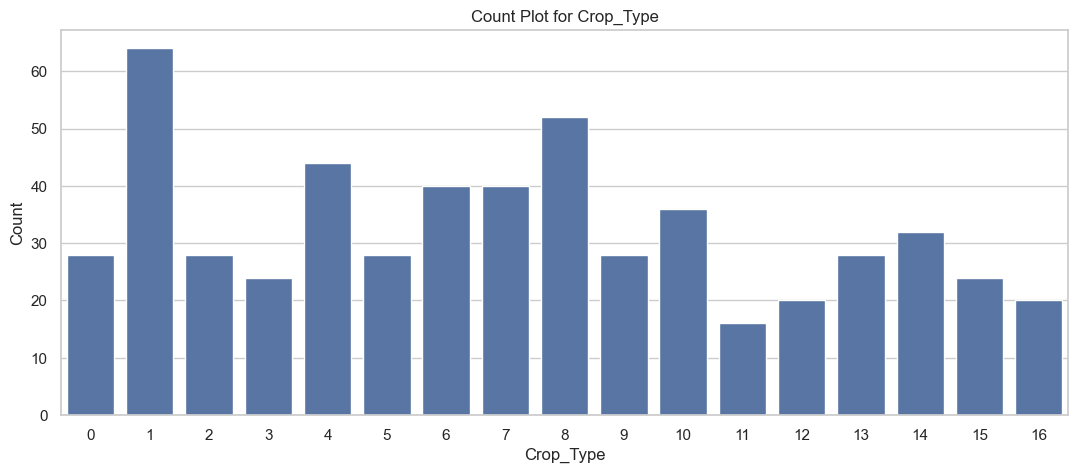

In [45]:
plt.figure(figsize=(13, 5))
sns.set(style="whitegrid")
sns.countplot(data=data, x='Crop_Type')
plt.title('Count Plot for Crop_Type')
plt.xlabel('Crop_Type')
plt.ylabel('Count')
plt.show()

In [46]:
#The plot that shows the count (frequency) of each unique crop type in the dataset
#The x-axis represents the different crop types.
#The y-axis represents the count (the number of occurrences) of each crop type in the dataset

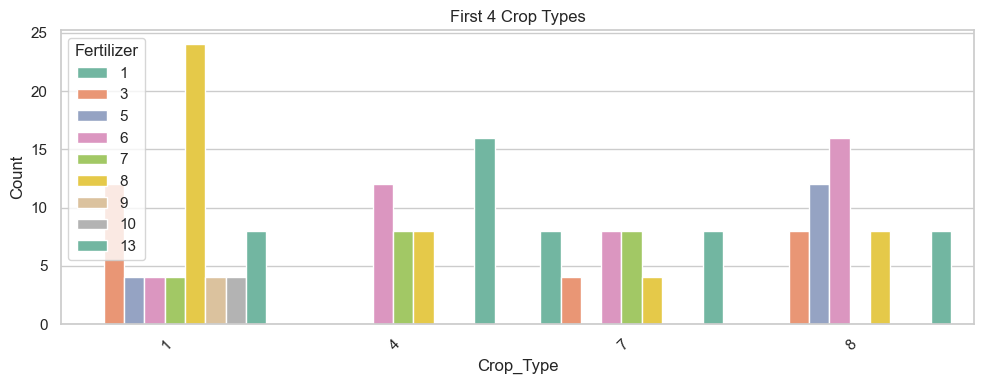

In [47]:

#first 4 crop types
part1_data = data[data['Crop_Type'].isin(data['Crop_Type'].value_counts().index[:4])]

# Create the first countplot
plt.figure(figsize=(10, 4))
sns.set(style="whitegrid")
sns.countplot(data=part1_data, x='Crop_Type', hue='Fertilizer', width=0.8, palette='Set2')
plt.title('First 4 Crop Types')
plt.xlabel('Crop_Type')
plt.ylabel('Count')
plt.legend(title='Fertilizer')
plt.xticks(rotation=45, horizontalalignment='right')
plt.tight_layout()
plt.show()


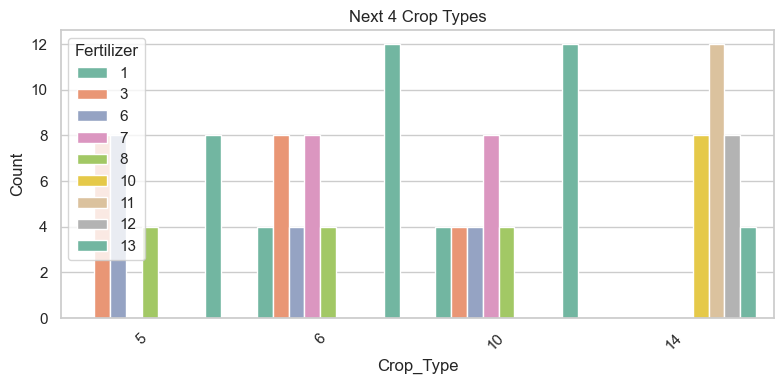

In [48]:
# Split the data into three parts: next 4 crop types
part2_data = data[data['Crop_Type'].isin(data['Crop_Type'].value_counts().index[4:8])]

# Create the second countplot
plt.figure(figsize=(8, 4))
sns.set(style="whitegrid")
sns.countplot(data=part2_data, x='Crop_Type', hue='Fertilizer', width=0.8, palette='Set2')
plt.title('Next 4 Crop Types')
plt.xlabel('Crop_Type')
plt.ylabel('Count')
plt.legend(title='Fertilizer')
plt.xticks(rotation=45, horizontalalignment='right')
plt.tight_layout()
plt.show()


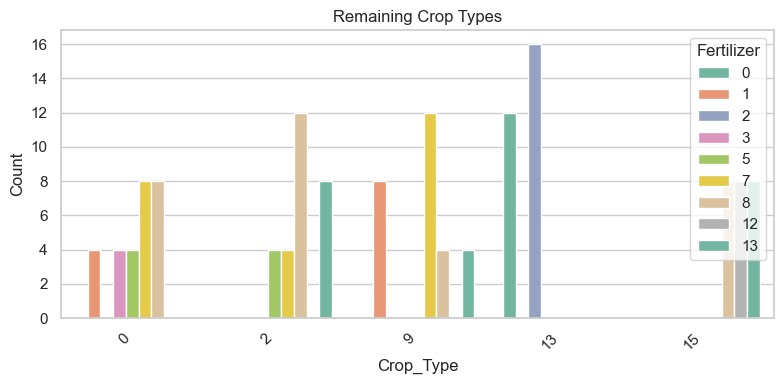

In [49]:
# Split the data into three parts: remaining crop types
part3_data = data[data['Crop_Type'].isin(data['Crop_Type'].value_counts().index[8:13])]

# Create the third countplot
plt.figure(figsize=(8, 4))
sns.set(style="whitegrid")
sns.countplot(data=part3_data, x='Crop_Type', hue='Fertilizer', width=0.8, palette='Set2')
plt.title('Remaining Crop Types')
plt.xlabel('Crop_Type')
plt.ylabel('Count')
plt.legend(title='Fertilizer')
plt.xticks(rotation=45, horizontalalignment='right')
plt.tight_layout()
plt.show()


In [50]:
#  this plot is provides insights into how different crop types are distributed based on the type of fertilizer used.
# The x-axis represents the different crop types.
# The y-axis represents the count (the number of occurrences) of each crop type in the dataset.

<Axes: >

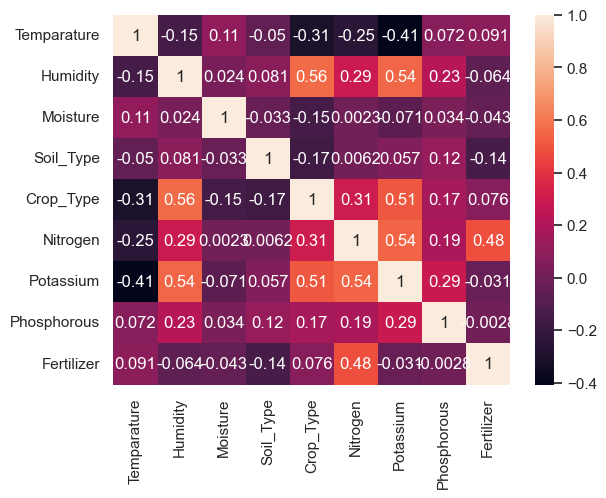

In [51]:
#Heatmap for Correlation Analysis
sns.heatmap(data.select_dtypes(include=['number']).corr(),annot=True)

In [52]:
#here is no such correlation between any of variables.. 

In [53]:
#encoding the labels for categorical variables
from sklearn.preprocessing import LabelEncoder
#it  transforming non-numeric data into a numeric format

In [54]:
#encoding Soil Type variable (safe — will skip if already numeric)
from sklearn.preprocessing import LabelEncoder
if 'Soil_Type' in data.columns:
    if data['Soil_Type'].dtype == 'object' or not pd.api.types.is_numeric_dtype(data['Soil_Type']):
        encode_soil = LabelEncoder()
        data['Soil_Type'] = encode_soil.fit_transform(data['Soil_Type'].astype(str))
        Soil_Type = pd.DataFrame(zip(encode_soil.classes_,encode_soil.transform(encode_soil.classes_)),columns=['Original','Encoded']).set_index('Original')
        display(Soil_Type)
    else:
        print('Soil_Type already encoded or numeric — skipping')
else:
    print('Soil_Type column not found')

Soil_Type already encoded or numeric — skipping


In [55]:
#encoding Crop Type variable (safe — will skip if already numeric)
from sklearn.preprocessing import LabelEncoder
if 'Crop_Type' in data.columns:
    if data['Crop_Type'].dtype == 'object' or not pd.api.types.is_numeric_dtype(data['Crop_Type']):
        encode_crop = LabelEncoder()
        data['Crop_Type'] = encode_crop.fit_transform(data['Crop_Type'].astype(str))
        Crop_Type = pd.DataFrame(zip(encode_crop.classes_,encode_crop.transform(encode_crop.classes_)),columns=['Original','Encoded']).set_index('Original')
        display(Crop_Type)
    else:
        print('Crop_Type already encoded or numeric — skipping')
else:
    print('Crop_Type column not found')

Crop_Type already encoded or numeric — skipping


In [56]:
#encoding Fertilizer variable (safe — will skip if already numeric)
from sklearn.preprocessing import LabelEncoder
if 'Fertilizer' in data.columns:
    if data['Fertilizer'].dtype == 'object' or not pd.api.types.is_numeric_dtype(data['Fertilizer']):
        encode_ferti = LabelEncoder()
        data['Fertilizer'] = encode_ferti.fit_transform(data['Fertilizer'].astype(str))
        Fertilizer = pd.DataFrame(zip(encode_ferti.classes_,encode_ferti.transform(encode_ferti.classes_)),columns=['Original','Encoded']).set_index('Original')
        display(Fertilizer)
    else:
        print('Fertilizer already encoded or numeric — skipping')
else:
    print('Fertilizer column not found')

Fertilizer already encoded or numeric — skipping


In [57]:
#splitting the data into train and test
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(data.drop('Fertilizer',axis=1),data.Fertilizer,test_size=0.2,random_state=1)
print('Shape of Splitting :')
print('x_train = {}, y_train = {}, x_test = {}, y_test = {}'.format(x_train.shape,y_train.shape,x_test.shape,y_test.shape))

Shape of Splitting :
x_train = (441, 8), y_train = (441,), x_test = (111, 8), y_test = (111,)


In [58]:
# here 20% of the data should be used for testing (evaluation), and the remaining 80% is used for training
#x_train and x_test = contain the features (independent variables) used for training and testing the model
#y_train and y_test = contains the labels(dependent variable) used for training and testing the model.

In [59]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 441 entries, 213 to 37
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Temparature  441 non-null    int64
 1   Humidity     441 non-null    int64
 2   Moisture     441 non-null    int64
 3   Soil_Type    441 non-null    int64
 4   Crop_Type    441 non-null    int64
 5   Nitrogen     441 non-null    int64
 6   Potassium    441 non-null    int64
 7   Phosphorous  441 non-null    int64
dtypes: int64(8)
memory usage: 31.0 KB


In [60]:
acc = [] # TEST
model = []
acc1=[] # TRIAN

### Logistic regression model

In [61]:
#importing libraries
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn import metrics
from sklearn import tree
import warnings
warnings.filterwarnings('ignore')

ds = DecisionTreeClassifier(criterion="entropy",random_state=2,max_depth=5)
ds.fit(x_train,y_train)

predicted_values_test = ds.predict(x_test)
x = metrics.accuracy_score(y_test, predicted_values_test)
acc.append(x)
model.append('Decision Tree')

predicted_values_train = ds.predict(x_train)
y = metrics.accuracy_score(y_train, predicted_values_train)
acc1.append(y)

print("DecisionTrees's Accuracy is: ", x*100, y*100)

print(classification_report(y_test, predicted_values_test))

DecisionTrees's Accuracy is:  90.09009009009009 93.42403628117914
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      0.80      0.89        10
           2       1.00      1.00      1.00         1
           3       1.00      1.00      1.00        12
           4       0.67      1.00      0.80         4
           5       1.00      1.00      1.00         6
           6       1.00      1.00      1.00        13
           7       1.00      1.00      1.00        14
           8       0.92      0.75      0.83        16
           9       0.00      0.00      0.00         1
          10       0.33      1.00      0.50         2
          11       0.00      0.00      0.00         3
          12       0.64      1.00      0.78         7
          13       1.00      0.94      0.97        18

    accuracy                           0.90       111
   macro avg       0.75      0.82      0.77       111
weighted avg  

In [62]:
from sklearn.naive_bayes import GaussianNB

NaiveBayes = GaussianNB()

NaiveBayes.fit(x_train,y_train)

predicted_values_test = NaiveBayes.predict(x_test)
x = metrics.accuracy_score(y_test, predicted_values_test)
acc.append(x)

predicted_values_train = NaiveBayes.predict(x_train)
y = metrics.accuracy_score(y_train, predicted_values_train)
acc1.append(y)

model.append('Naive Bayes')
print("Naive Bayes's Accuracy is: ", x,y)

print(classification_report(y_test, predicted_values_test))

Naive Bayes's Accuracy is:  0.9459459459459459 0.9138321995464853
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00        10
           2       1.00      1.00      1.00         1
           3       1.00      1.00      1.00        12
           4       1.00      1.00      1.00         4
           5       1.00      1.00      1.00         6
           6       1.00      1.00      1.00        13
           7       1.00      1.00      1.00        14
           8       0.88      0.88      0.88        16
           9       1.00      1.00      1.00         1
          10       1.00      1.00      1.00         2
          11       0.60      1.00      0.75         3
          12       0.75      0.86      0.80         7
          13       1.00      0.83      0.91        18

    accuracy                           0.95       111
   macro avg       0.94      0.97      0.95       111
weighted avg  

In [63]:
from sklearn.svm import SVC
# data normalization with sklearn
from sklearn.preprocessing import MinMaxScaler
# fit scaler on training data
norm = MinMaxScaler().fit(x_train)
X_train_norm = norm.transform(x_train)
# transform testing data
X_test_norm = norm.transform(x_test)
SVM = SVC(kernel='poly', degree=3, C=1)
SVM.fit(X_train_norm,y_train)

predicted_values_test = SVM.predict(X_test_norm)
x = metrics.accuracy_score(y_test, predicted_values_test)
acc.append(x)

predicted_values_train = SVM.predict(X_train_norm)
y = metrics.accuracy_score(y_train, predicted_values_train)
acc1.append(y)

model.append('SVM')
print("SVM's Accuracy is: ", x,y)

print(classification_report(y_test, predicted_values_test))

SVM's Accuracy is:  0.990990990990991 0.9931972789115646
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00        10
           2       1.00      1.00      1.00         1
           3       1.00      1.00      1.00        12
           4       1.00      1.00      1.00         4
           5       1.00      1.00      1.00         6
           6       1.00      1.00      1.00        13
           7       1.00      1.00      1.00        14
           8       1.00      1.00      1.00        16
           9       1.00      1.00      1.00         1
          10       1.00      1.00      1.00         2
          11       0.75      1.00      0.86         3
          12       1.00      1.00      1.00         7
          13       1.00      0.94      0.97        18

    accuracy                           0.99       111
   macro avg       0.98      1.00      0.99       111
weighted avg       0.99

In [64]:
from sklearn.linear_model import LogisticRegression

LogReg = LogisticRegression(random_state=2)

LogReg.fit(x_train,y_train)

predicted_values_test = LogReg.predict(x_test)
x = metrics.accuracy_score(y_test, predicted_values_test)
acc.append(x)

predicted_values_train = LogReg.predict(x_train)
y = metrics.accuracy_score(y_train, predicted_values_train)
acc1.append(y)

model.append('Logistic Regression')
print("Logistic Regression's Accuracy is: ", x,y)

print(classification_report(y_test, predicted_values_test))

Logistic Regression's Accuracy is:  0.7837837837837838 0.909297052154195
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         4
           1       1.00      1.00      1.00        10
           2       0.33      1.00      0.50         1
           3       0.90      0.75      0.82        12
           4       1.00      0.25      0.40         4
           5       1.00      1.00      1.00         6
           6       1.00      1.00      1.00        13
           7       1.00      1.00      1.00        14
           8       0.58      0.69      0.63        16
           9       0.00      0.00      0.00         1
          10       1.00      0.50      0.67         2
          11       0.50      0.33      0.40         3
          12       0.25      0.29      0.27         7
          13       0.73      0.89      0.80        18

    accuracy                           0.78       111
   macro avg       0.73      0.66      0.65       111
weighte

In [65]:
from sklearn.ensemble import RandomForestClassifier

RF = RandomForestClassifier(n_estimators=20, random_state=0)
RF.fit(x_train,y_train)

predicted_values_test = RF.predict(x_test)
x = metrics.accuracy_score(y_test, predicted_values_test)
acc.append(x)

predicted_values_train = RF.predict(x_train)
y = metrics.accuracy_score(y_train, predicted_values_train)
acc1.append(y)

model.append('RF')
print("RF's Accuracy is: ", x,y)

print(classification_report(y_test, predicted_values_test))

RF's Accuracy is:  1.0 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00        10
           2       1.00      1.00      1.00         1
           3       1.00      1.00      1.00        12
           4       1.00      1.00      1.00         4
           5       1.00      1.00      1.00         6
           6       1.00      1.00      1.00        13
           7       1.00      1.00      1.00        14
           8       1.00      1.00      1.00        16
           9       1.00      1.00      1.00         1
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         7
          13       1.00      1.00      1.00        18

    accuracy                           1.00       111
   macro avg       1.00      1.00      1.00       111
weighted avg       1.00      1.00      1.00       111

In [66]:
from sklearn.model_selection import cross_val_score

score = cross_val_score(RF,data,data.Fertilizer,cv=5)
print("Cross-validation score of RF is:",score)
score = cross_val_score(LogReg,data,data.Fertilizer,cv=5)
print("Cross-validation score of LogReg is:",score)
score = cross_val_score(SVM,data,data.Fertilizer,cv=5)
print("Cross-validation score of SVM is:",score)
score = cross_val_score(NaiveBayes,data,data.Fertilizer,cv=5)
print("Cross-validation score of NaiveBayes is:",score)
score = cross_val_score(ds, data, data.Fertilizer,cv=5)
print("Cross-validation score of ds is:",score)

Cross-validation score of RF is: [1. 1. 1. 1. 1.]
Cross-validation score of LogReg is: [0.97297297 0.94594595 0.91818182 0.88181818 0.87272727]
Cross-validation score of SVM is: [0.96396396 0.92792793 0.91818182 0.88181818 0.98181818]
Cross-validation score of NaiveBayes is: [1. 1. 1. 1. 1.]
Cross-validation score of ds is: [1. 1. 1. 1. 1.]
Cross-validation score of LogReg is: [0.97297297 0.94594595 0.91818182 0.88181818 0.87272727]
Cross-validation score of SVM is: [0.96396396 0.92792793 0.91818182 0.88181818 0.98181818]
Cross-validation score of NaiveBayes is: [1. 1. 1. 1. 1.]
Cross-validation score of ds is: [1. 1. 1. 1. 1.]


<Axes: title={'center': 'Accuracy Comparison'}, xlabel='Accuracy', ylabel='Algorithm'>

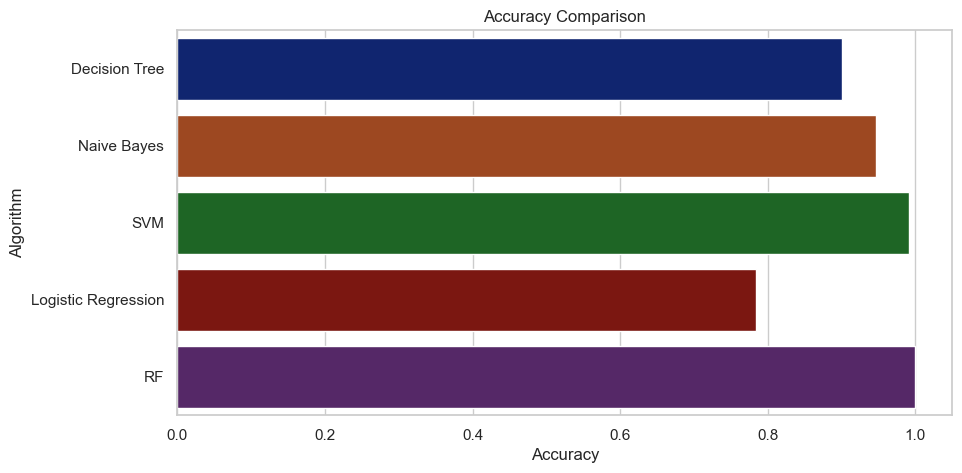

In [67]:
plt.figure(figsize=[10,5],dpi = 100)
plt.title('Accuracy Comparison')
plt.xlabel('Accuracy')
plt.ylabel('Algorithm')
sns.barplot(x = acc,y = model,palette='dark')

In [68]:
#pickling the file
import pickle
pickle_out = open('classifier.pkl','wb')
pickle.dump(RF,pickle_out)
pickle_out.close()

In [69]:
model = pickle.load(open('classifier.pkl','rb'))
model.predict([[34,67,62,0,1,7,0,30]])

array([6])

In [70]:
model = pickle.load(open('classifier.pkl','rb'))
model.predict([[25,78,43,4,1,22,26,38]])

array([10])

In [71]:
#pickling the file
import pickle
pickle_out = open('fertilizer.pkl','wb')
pickle.dump(encode_ferti,pickle_out)
pickle_out.close()

In [72]:
ferti = pickle.load(open('fertilizer.pkl','rb'))
ferti.classes_[1]

'10-26-26'

In [ ]:
# --- IGNORE ---